In [1]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path.home() / "steam-oyun-asistani"
RAW = ROOT / "data" / "raw"
GAMES_PATH = RAW / "games.json"
REVIEWS_DIR = RAW / "reviews"

print(GAMES_PATH.exists(), round(GAMES_PATH.stat().st_size / 1e6, 1), "MB")
print(REVIEWS_DIR.exists(), sum(1 for _ in REVIEWS_DIR.glob("*.csv")), "CSV")

with open(GAMES_PATH, encoding="utf-8") as f:
    print(f.read(1500))

True 268.8 MB
True 23107 CSV
{
    "1724540": {
        "name": "Welcome to Goodland",
        "release_date": "Apr 28, 2023",
        "required_age": 0,
        "price": 16.99,
        "detailed_description": "Join our Discord! About the Game You could never have known you would end up in a situation like this, yet here you are: helping a Mexican cartel with money laundering. The cartel doesn’t listen to excuses and rarely gives second chances. You would not wish to disappoint them. You know what happened to the last person who did. And so, you start small in a secluded town in Minnesota, surrounded by beautiful forests filled with dark secrets. There are several factions already in play here, and they will not want to share their influence with a rising force… but can you survive without allies? You will need all your courage, ingenuity and perseverance to overcome the challenges before you. Even those closest to you might betray you, but you might find allies in the most unexpected 

In [2]:
with open(GAMES_PATH, encoding="utf-8") as f:
    games_raw = json.load(f)

print(type(games_raw).__name__, len(games_raw), "oyun")

ilk_id = next(iter(games_raw))
print("Örnek app_id:", ilk_id)

for alan, deger in games_raw[ilk_id].items():
    print(f"{alan:28} {type(deger).__name__:6} {str(deger)[:70]}")

dict 65686 oyun
Örnek app_id: 1724540
name                         str    Welcome to Goodland
release_date                 str    Apr 28, 2023
required_age                 int    0
price                        float  16.99
detailed_description         str    Join our Discord! About the Game You could never have known you would 
about_the_game               str    You could never have known you would end up in a situation like this, 
short_description            str    It is a strategy/adventure game set in a small, quiet town. Survive as
supported_languages          list   ['English']
full_audio_languages         list   []
categories                   list   ['Single-player', 'Steam Achievements', 'Family Sharing']
genres                       list   ['Adventure', 'Indie', 'Simulation', 'Strategy']
positive                     int    25
negative                     int    8
estimated_owners             str    0 - 20000
average_playtime_forever     int    0
average_playtime_2weeks      

In [4]:
print(games_raw[ilk_id]["tags"])

{'Choose Your Own Adventure': 332, 'Time Management': 326, 'Political Sim': 321, 'Puzzle': 317, 'Turn-Based Strategy': 315, 'Drama': 313, 'Visual Novel': 313, 'Simulation': 311, 'Interactive Fiction': 306, 'Strategy': 303, '2D': 299, 'Comic Book': 294, 'Isometric': 290, 'Choices Matter': 290, 'Multiple Endings': 284, 'Story Rich': 278, 'Economy': 275, 'Management': 263, 'Political': 249, 'Casual': 243}


## games.json yapısı

- En dışta **sözlük**: anahtar `app_id` (string), değer oyunun bilgileri.
- `app_id` kaydın içinde ayrı alan olarak **yok**, tabloya çevirirken anahtardan sütun yapılacak.
- Toplam **65.686 oyun**.

### Alan tipleri
| Tip | Alanlar |
|---|---|
| Liste | supported_languages, full_audio_languages, categories, genres |
| Sözlük | tags (etiket → oy veren oyuncu sayısı) |
| Metin | name, detailed_description, about_the_game, short_description |
| Sayı | required_age, price, positive, negative, playtime alanları, peak_ccu |

### 02'de dikkat edilecekler
- `release_date` metin ("Apr 28, 2023"), tarihe çevrilmeli.
- `estimated_owners` metin aralık ("0 - 20000"), alt/üst sınır sayıya ayrılabilir.
- `discount` sayı olması gerekirken metin ("0").
- Üç açıklama alanı var, içerikleri büyük ölçüde tekrar ediyor olabilir. Chroma'ya hangisinin gideceğine karar verilecek.
- Liste ve sözlük alanları SQLite'a düz sütun olarak sığmaz, ayrı tablo gerekecek.

In [5]:
print(json.dumps(games_raw[ilk_id], indent=2, ensure_ascii=False))

{
  "name": "Welcome to Goodland",
  "release_date": "Apr 28, 2023",
  "required_age": 0,
  "price": 16.99,
  "detailed_description": "Join our Discord! About the Game You could never have known you would end up in a situation like this, yet here you are: helping a Mexican cartel with money laundering. The cartel doesn’t listen to excuses and rarely gives second chances. You would not wish to disappoint them. You know what happened to the last person who did. And so, you start small in a secluded town in Minnesota, surrounded by beautiful forests filled with dark secrets. There are several factions already in play here, and they will not want to share their influence with a rising force… but can you survive without allies? You will need all your courage, ingenuity and perseverance to overcome the challenges before you. Even those closest to you might betray you, but you might find allies in the most unexpected places. Plan your actions, acquire businesses, protect and promote your busi

## Örnek kayıt (1724540) incelemesi
- Bir oyunda 21 alan var, son alan `tags`.
- `detailed_description` ≈ "Join our Discord! About the Game " + `about_the_game` → tekrar. Chroma için biri seçilecek.
- **Geliştirici / yayıncı / platform alanı yok** → bu tür sorular kapsam dışı.
- `tags` oyları (332) yorum sayısından (33) büyük → farklı ölçüler, karıştırılmamalı.

In [6]:
pd.set_option("display.width", 200)

alan_setleri = pd.Series([tuple(sorted(oyun.keys())) for oyun in games_raw.values()])
print(alan_setleri.value_counts().size, "farklı alan seti\n")

coklu_alanlar = ["tags", "genres", "categories", "supported_languages", "full_audio_languages"]
uzunluklar = pd.DataFrame({
    alan: [len(oyun.get(alan) or []) for oyun in games_raw.values()]
    for alan in coklu_alanlar
})

print(uzunluklar.describe().T, "\n")
print(uzunluklar["tags"].value_counts().sort_index())

1 farklı alan seti

                        count       mean        std  min  25%   50%   75%    max
tags                  65686.0  11.180800   8.582726  0.0  0.0  14.0  20.0   20.0
genres                65686.0   2.688716   1.534442  0.0  2.0   3.0   4.0   19.0
categories            65686.0   3.589243   2.574538  0.0  2.0   3.0   5.0   23.0
supported_languages   65686.0   5.253326  14.170516  0.0  1.0   1.0   4.0  103.0
full_audio_languages  65686.0   2.258031  12.194468  0.0  0.0   0.0   1.0  103.0 

tags
0     20900
1        50
2        78
3       118
4       131
5      1051
6       935
7      1107
8      1122
9      1157
10     1256
11     1388
12     1457
13     1557
14     1676
15     1728
16     1840
17     1995
18     1956
19     1845
20    22339
Name: count, dtype: int64


## Çoklu alanların oyun başına eleman sayısı
- 65.686 oyunun hepsinde aynı 21 alan var → yapı tutarlı.
- **tags:** İki uçlu dağılım. %32'sinde (20.900) hiç etiket yok, %34'ünde (22.339) tam 20. Steam üst sınırı 20. 1–4 etiketli oyun neredeyse yok. Ortalama (11,2) bu yüzden yanıltıcı.
- **genres:** medyan 3, max 19 → şüpheli, kontrol edilecek.
- **categories:** medyan 3, sorunsuz.
- **supported_languages:** medyan 1, max 103 → şüpheli (bozuk ayrıştırma olabilir).
- **full_audio_languages:** %75'inde 0 → az bilgi taşıyor.

### Karar taslağı
- SQLite: etiketlerin hepsi ayrı tabloda (app_id, etiket, oy, sıra).
- Chroma metni: ilk N etiket (N alt küme seçilince belirlenecek).
- Açık soru: etiketsiz oyunlar yorumsuz küçük oyunlar mı?

In [7]:
uzunluklar.index = list(games_raw.keys())
uzunluklar["toplam_oy"] = [oyun["positive"] + oyun["negative"] for oyun in games_raw.values()]

oy_grubu = pd.cut(
    uzunluklar["toplam_oy"],
    bins=[-1, 0, 9, 49, 499, float("inf")],
    labels=["0", "1-9", "10-49", "50-499", "500+"],
)
etiket_var = (uzunluklar["tags"] > 0).rename("etiket_var")

print(pd.crosstab(oy_grubu, etiket_var, margins=True))

etiket_var  False   True    All
toplam_oy                      
0           20899    153  21052
1-9             1  17633  17634
10-49           0  14364  14364
50-499          0   8607   8607
500+            0   4029   4029
All         20900  44786  65686


## Etiketsiz oyunlar ↔ toplam oy (positive + negative)
| toplam_oy | etiket yok | etiket var | toplam |
|---|---|---|---|
| 0 | 20.899 | 153 | 21.052 |
| 1-9 | 1 | 17.633 | 17.634 |
| 10-49 | 0 | 14.364 | 14.364 |
| 50-499 | 0 | 8.607 | 8.607 |
| 500+ | 0 | 4.029 | 4.029 |

- Etiketsiz oyunların neredeyse tamamı (20.899 / 20.900) **hiç oy almamış** oyunlar.
- %32 oyunun (21.052) hiç oyu yok → oran hesaplanamaz, alt kümeye alınmaz.
- Sonuç: Oyu olan oyunlar seçilince etiket eksikliği sorunu kalmıyor.
- 500+ oylu 4.029, 50–499 oylu 8.607 oyun var.
- Açık soru: 23.107 yorum CSV'si ↔ 44.634 oylu oyun, eşleşme CSV adımında kontrol edilecek.

In [8]:
for alan in ["genres", "supported_languages"]:
    en_cok = uzunluklar[alan].idxmax()
    print(f"--- {alan}: {en_cok} ({games_raw[en_cok]['name']}), {uzunluklar.loc[en_cok, alan]} eleman")
    print(games_raw[en_cok][alan], "\n")

for alan in ["genres", "supported_languages"]:
    sayac = pd.Series([deger for oyun in games_raw.values() for deger in oyun[alan]]).value_counts()
    print(f"=== {alan}: {sayac.size} farklı değer")
    print(sayac.to_string(), "\n")

--- genres: 1434230 (CAT SUDOKU🐱), 19 eleman
['Casual', 'Indie', 'Accounting', 'Animation & Modeling', 'Audio Production', 'Design & Illustration', 'Education', 'Photo Editing', 'Software Training', 'Utilities', 'Video Production', 'Web Publishing', 'Game Development', 'Movie', 'Documentary', 'Episodic', 'Short', 'Tutorial', '360 Video'] 

--- supported_languages: 2947750 (Hidden Old House Top-Down 3D), 103 eleman
['English', 'French', 'Italian', 'German', 'Spanish - Spain', 'Arabic', 'Bulgarian', 'Czech', 'Danish', 'Dutch', 'Finnish', 'Greek', 'Hungarian', 'Indonesian', 'Japanese', 'Korean', 'Norwegian', 'Polish', 'Portuguese - Brazil', 'Portuguese - Portugal', 'Romanian', 'Russian', 'Simplified Chinese', 'Spanish - Latin America', 'Swedish', 'Thai', 'Traditional Chinese', 'Turkish', 'Ukrainian', 'Vietnamese', 'Afrikaans', 'Albanian', 'Amharic', 'Armenian', 'Assamese', 'Azerbaijani', 'Bangla', 'Basque', 'Belarusian', 'Bosnian', 'Catalan', 'Cherokee', 'Croatian', 'Dari', 'Estonian', 'F

## Şüpheli kayıtlar: bozuk değil, "hepsini işaretle" spam'i
### genres (30 farklı değer, hepsi Steam'in resmi türleri)
- En uç örnek: 1434230 CAT SUDOKU, 19 tür (her şeyi işaretlemiş).
- Movie, Documentary, Short, Tutorial, 360 Video, Violent → 1'er kez, yok sayılabilir.
- Yazılım türleri (Utilities, Design & Illustration, Animation & Modeling, Game Development, Education, Video/Audio Production, Photo Editing, Software Training, Web Publishing, Accounting) → oyun değil, alt kümeden çıkarılması düşünülecek.
- Early Access, Free To Play → tür değil durum, ama soru-cevap için faydalı.

### supported_languages (103 farklı değer)
- Nadir dillerin hepsi ~1.165–1.240 kez → ~1.170 oyun 103 dilin hepsini işaretlemiş.
- Dil sayısı ve nadir diller güvenilmez. Büyük diller güvenilir.
- Turkish: 5.939 oyun → Türkçe sorular için malzeme.

In [9]:
games = pd.DataFrame.from_dict(games_raw, orient="index")
games.index.name = "app_id"
print(games.shape, "\n")

def bos_mu(deger):
    if isinstance(deger, str):
        return deger.strip() == ""
    if isinstance(deger, (list, dict)):
        return len(deger) == 0
    return pd.isna(deger)

bos_sayisi = games.map(bos_mu).sum()
sayisal = games.select_dtypes(include="number").columns

ozet = pd.DataFrame({
    "tip": games.dtypes.astype(str),
    "bos": bos_sayisi,
    "bos_%": (bos_sayisi / len(games) * 100).round(1),
    "sifir": (games[sayisal] == 0).sum(),
})
print(ozet.to_string())

(65686, 21) 

                              tip    bos  bos_%    sifir
about_the_game                str   5119    7.8      NaN
average_playtime_2weeks     int64      0    0.0  65192.0
average_playtime_forever    int64      0    0.0  62231.0
categories                 object   5312    8.1      NaN
detailed_description          str   5097    7.8      NaN
discount                   object      0    0.0      NaN
estimated_owners              str      0    0.0      NaN
full_audio_languages       object  39598   60.3      NaN
genres                     object   5100    7.8      NaN
median_playtime_2weeks      int64      0    0.0  65192.0
median_playtime_forever     int64      0    0.0  62231.0
name                          str      1    0.0      NaN
negative                    int64      0    0.0  32199.0
peak_ccu                    int64      0    0.0  54046.0
positive                    int64      0    0.0  22834.0
price                     float64      0    0.0  14958.0
release_date     

## Oyun tablosu: tipler ve eksikler (65.686 × 21)
"Boş" = boş metin / boş liste / NaN (JSON eksikleri null değil "" ve [] olarak tutuyor).

### Eksikler
- ~5.100 oyunda (%7,8) açıklamalar, genres, supported_languages, categories boş → muhtemelen aynı "iskelet" kayıtlar (kontrol edilecek).
- tags %31,8 boş (= oysuz oyunlar), full_audio_languages %60 boş.
- name: 1 boş. release_date, estimated_owners: hiç boş yok.

### Sıfırlar (0 ≠ her zaman eksik)
| sütun | sıfır % | yorum |
|---|---|---|
| *_playtime_forever | 94,7 | 0 = veri yok → NULL yapılacak |
| *_playtime_2weeks | 99,2 | anlık değer → atılacak |
| required_age | 99,4 | bilgi yok → atılabilir |
| peak_ccu | 82 | anlık değer, dikkat |
| price | 23 | **gerçek bilgi**: ücretsiz oyun |

- positive=0: 22.834, toplam oy=0: 21.052 → ~1.780 oyun sadece olumsuz oylu (%0 oran). Az oyda oran oynak → **minimum oy eşiği** gerekecek.

### Tip sorunları
- discount: `object` (karışık tip olabilir) → kontrol edilecek.
- release_date ("Apr 28, 2023") → tarih, estimated_owners ("0 - 20000") → alt/üst sayı.

In [10]:
bos = games.map(bos_mu)

iskelet_sutunlar = ["about_the_game", "detailed_description", "short_description",
                    "genres", "supported_languages", "categories"]
kac_bos = bos[iskelet_sutunlar].sum(axis=1)
print("Oyun başına bu 6 sütundan kaçı boş:")
print(kac_bos.value_counts().sort_index(), "\n")

iskelet = kac_bos == len(iskelet_sutunlar)
toplam_oy = games["positive"] + games["negative"]
print("İskelet kayıt sayısı:", iskelet.sum())
print("İskeletlerin toplam oyu:")
print(toplam_oy[iskelet].describe(), "\n")

print("discount değerlerinin tipleri:")
print(games["discount"].map(lambda x: type(x).__name__).value_counts(), "\n")
print("discount değerleri:")
print(games["discount"].value_counts().to_string(), "\n")

print("Adı boş olan oyun:")
print(games[bos["name"]].T.to_string())

Oyun başına bu 6 sütundan kaçı boş:
0    59926
1      653
2       50
3       22
4        7
5      211
6     4817
Name: count, dtype: int64 

İskelet kayıt sayısı: 4817
İskeletlerin toplam oyu:
count    4817.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
dtype: float64 

discount değerlerinin tipleri:
discount
str    52165
int    13521
Name: count, dtype: int64 

discount değerleri:
discount
0     48683
0     13521
50      443
20      293
30      290
40      274
51      247
80      220
10      199
90      192
60      182
70      175
75      165
25      158
15       92
35       78
85       44
72       43
65       39
45       32
95       29
33       28
55       26
67       17
86       13
92       13
66       12
17       10
34        8
32        8
21        8
37        8
88        7
26        6
73        6
38        6
91        5
61        4
69        4
89        4
27        4
18        4
47        4
11        4
36        4

## Şüphelilerin kontrolü
### İskelet kayıtlar
6 sütun (3 açıklama, genres, supported_languages, categories) için oyun başına boş sayısı:
| boş | oyun |
|---|---|
| 0 | 59.926 |
| 1–5 | 943 |
| 6 | 4.817 |
- 4.817 iskelet kaydın **hepsinin toplam oyu 0** → oy filtresiyle kendiliğinden elenir.
- 943 kısmen eksik oyun → alt küme seçildikten sonra kontrol edilecek.

### discount
- Metin "0" (48.683) + sayı 0 (13.521) → aynı değer iki tip, sütun `object`.
- Sayı olanların hepsi 0; indirimler metin olarak tutulmuş. Çözüm: `pd.to_numeric`.
- 3.482 oyun (%5) veri çekildiği anda indirimdeymiş → anlık değer, "şu an indirimde mi" sorusu için kullanılamaz.
- Açık soru: `price` liste fiyatı mı, indirimli fiyat mı?

### Adı boş oyun
- 1347240: ad, açıklama, tür, etiket yok, oy 0, owners "0 - 0" → iskelet, oy filtresiyle elenir.

### Ana bulgu
Kirli kayıtların neredeyse hepsi oysuz oyunlar → **"toplam oy > eşik" filtresi temizliğin çoğunu tek başına yapar.**

In [11]:
oylu = games[toplam_oy > 0].copy()
oylu["toplam_oy"] = toplam_oy[toplam_oy > 0]
oylu["oran"] = oylu["positive"] / oylu["toplam_oy"]

oylu["oy_grubu"] = pd.cut(
    oylu["toplam_oy"],
    bins=[0, 9, 49, 99, 499, 999, 9_999, float("inf")],
    labels=["1-9", "10-49", "50-99", "100-499", "500-999", "1k-10k", "10k+"],
)

tablo = oylu.groupby("oy_grubu", observed=True)["oran"].agg(
    oyun="size",
    ortalama="mean",
    std="std",
    yuzde_0=lambda s: (s == 0).mean() * 100,
    yuzde_100=lambda s: (s == 1).mean() * 100,
).round(3)
print(tablo.to_string(), "\n")

print("Genel oran özeti:")
print(oylu["oran"].describe())

           oyun  ortalama    std  yuzde_0  yuzde_100
oy_grubu                                            
1-9       17634     0.742  0.331   10.043     49.127
10-49     14364     0.795  0.190    0.077     16.472
50-99      3501     0.809  0.148    0.000      2.714
100-499    5106     0.817  0.135    0.000      0.450
500-999    1266     0.822  0.124    0.000      0.000
1k-10k     2165     0.838  0.124    0.000      0.000
10k+        598     0.852  0.124    0.000      0.000 

Genel oran özeti:
count    44634.000000
mean         0.781100
std          0.247264
min          0.000000
25%          0.666667
50%          0.857143
75%          0.994764
max          1.000000
Name: oran, dtype: float64


## Olumlu oran (positive / (positive + negative)) ve oy sayısı
| oy grubu | oyun | ort. oran | std | %0 oranlı | %100 oranlı |
|---|---|---|---|---|---|
| 1-9 | 17.634 | 0,742 | 0,331 | 10,0 | 49,1 |
| 10-49 | 14.364 | 0,795 | 0,190 | 0,1 | 16,5 |
| 50-99 | 3.501 | 0,809 | 0,148 | 0 | 2,7 |
| 100-499 | 5.106 | 0,817 | 0,135 | 0 | 0,45 |
| 500-999 | 1.266 | 0,822 | 0,124 | 0 | 0 |
| 1k-10k | 2.165 | 0,838 | 0,124 | 0 | 0 |
| 10k+ | 598 | 0,852 | 0,124 | 0 | 0 |

- Az oyda oran gürültü (1–9 oyda oyunların yarısı tam %100).
- std 500 oyda 0,124'e oturuyor → kalan fark oyunlar arası gerçek fark.
- Genel medyan 0,857 → Steam iyimser; "%80 olumlu" ortalamanın altı (agent bunu bilmeli).
- Steam'in kendi eşikleri (10 / 50 / 500 değerlendirme) bu kırılmalarla örtüşüyor.

### Eşik adayları
≥50 → 12.636 oyun · **≥100 → 9.135 oyun (öneri)** · ≥500 → 4.029 oyun
Son karar yorum CSV'leri incelendikten sonra.

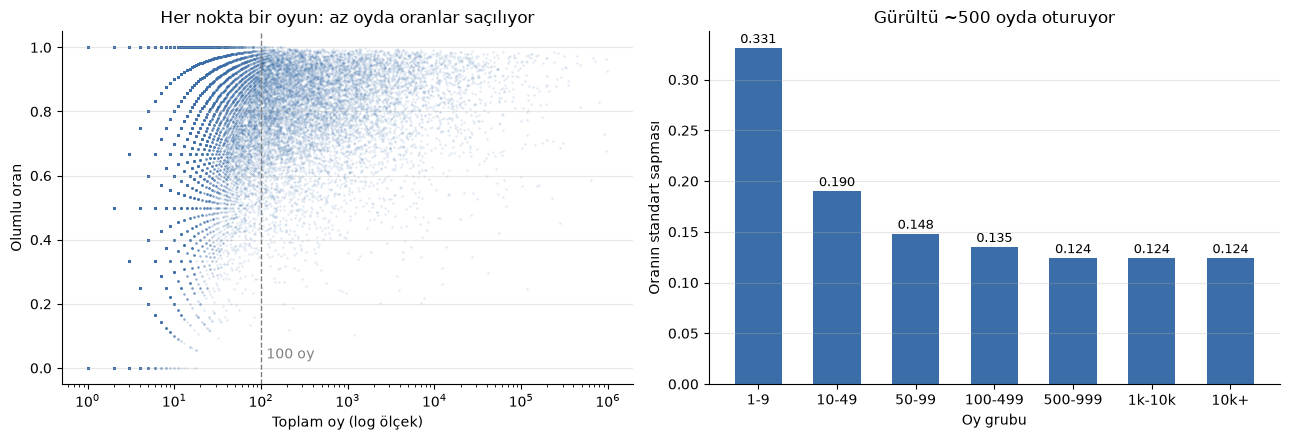

In [12]:
import matplotlib.pyplot as plt

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.scatter(oylu["toplam_oy"], oylu["oran"], s=3, alpha=0.15, color="#3b6ea8", linewidths=0)
ax1.set_xscale("log")
ax1.axvline(100, color="gray", linestyle="--", linewidth=1)
ax1.text(115, 0.03, "100 oy", color="gray")
ax1.set_xlabel("Toplam oy (log ölçek)")
ax1.set_ylabel("Olumlu oran")
ax1.set_title("Her nokta bir oyun: az oyda oranlar saçılıyor")

ax2.bar(tablo.index.astype(str), tablo["std"], color="#3b6ea8", width=0.6)
for x, y in enumerate(tablo["std"]):
    ax2.text(x, y + 0.005, f"{y:.3f}", ha="center", fontsize=9)
ax2.set_xlabel("Oy grubu")
ax2.set_ylabel("Oranın standart sapması")
ax2.set_title("Gürültü ~500 oyda oturuyor")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(FIG_DIR / "oran_oy_huni.png", dpi=150)
plt.show()

### Grafik: oran ↔ oy sayısı (reports/figures/oran_oy_huni.png)
- **Sol:** Huni şekli. Az oyda oranlar 0–1 arasına saçılıyor, çok oyda 0,75–0,95'e toplanıyor.
  - Kavisler = az oyda oranın alabileceği kesirler (k/n). En üst kavis "1 olumsuz oy", sonraki "2 olumsuz oy"...
  - ~100 oydan sonra kavisler bulutta kayboluyor → eşik önerisini destekliyor.
  - 10⁴+ oylu ama düşük oranlı oyunlar = gerçekten tartışmalı oyunlar → RAG için değerli.
- **Sağ:** std 500 oyda 0,124'te düzleşiyor = oyunlar arası gerçek fark. 100–499 (0,135) plato değerine yakın.
**Sağ grafiği okuma:** Dağınıklık = gerçek kalite farkı + ölçüm şansı. Şans oy arttıkça azalır, gerçek fark sabit kalır. 500+ grupların üçü de 0,124 → şans bitti, 0,124 gerçek fark. 100–499'da (0,135) şans payı çok küçük → ≥100 eşiği az güvenilirlik kaybıyla veriyi ikiye katlıyor (9.135 vs 4.029 oyun).

In [13]:
csv_dosyalari = sorted(REVIEWS_DIR.glob("*.csv"))
print(len(csv_dosyalari), "dosya\n")

print("İlk 10 dosya adı:")
for p in csv_dosyalari[:10]:
    print(" ", p.name)

dosyalar = pd.DataFrame({
    "dosya": [p.name for p in csv_dosyalari],
    "mb": [p.stat().st_size / 1e6 for p in csv_dosyalari],
})

print("\nToplam:", round(dosyalar["mb"].sum() / 1000, 2), "GB\n")
print("Dosya boyutu (MB) özeti:")
print(dosyalar["mb"].describe(percentiles=[0.5, 0.9, 0.99]).round(3), "\n")
print("En büyük 10 dosya:")
print(dosyalar.sort_values("mb", ascending=False).head(10).to_string())

23107 dosya

İlk 10 dosya adı:
  1000000_37.csv
  1000030_2098.csv
  1000280_51.csv
  1000360_6765.csv
  1000410_2404.csv
  1000440_407.csv
  1000700_250.csv
  1000760_1316.csv
  1000770_210.csv
  1001270_4904.csv

Toplam: 10.55 GB

Dosya boyutu (MB) özeti:
count    23107.000
mean         0.456
std          2.332
min          0.003
50%          0.048
90%          0.665
99%          8.023
max         93.705
Name: mb, dtype: float64 

En büyük 10 dosya:
                    dosya         mb
21807   553850_336460.csv  93.704525
23069   990080_293388.csv  85.416589
16586  2357570_313125.csv  76.531853
18610   261550_253629.csv  71.113646
22669   892970_168438.csv  55.944595
16896   239140_179837.csv  52.390055
7902   1599340_201079.csv  52.311110
21788   534380_145768.csv  51.024249
5882   1468810_224207.csv  49.194863
21783   526870_194630.csv  45.895619


## Yorum CSV'leri: dosya düzeyi
- 23.107 dosya, toplam 10,55 GB.
- Ad formatı: `{app_id}_{sayı}.csv` (sayı muhtemelen yorum sayısı, doğrulanacak).
- Boyut: medyan 48 KB, %90 < 0,67 MB, %99 < 8 MB, max 94 MB (553850, Helldivers 2).
- En büyük dosya bile belleğe sığar → dosya dosya işlenecek, hepsi birden yüklenmeyecek.

In [14]:
parcalar = dosyalar["dosya"].str.removesuffix(".csv").str.split("_", expand=True)
print("Ad kaç parçaya ayrıldı:", parcalar.shape[1])

dosyalar["app_id"] = parcalar[0]
dosyalar["n"] = parcalar[1].astype(int)

print("Tekrarlı app_id:", dosyalar["app_id"].duplicated().sum())
print("Adlardaki sayıların toplamı:", f"{dosyalar['n'].sum():,}", "\n")

dosyalar["games_te_var"] = dosyalar["app_id"].isin(games.index)
print(dosyalar["games_te_var"].value_counts(), "\n")

dosyalar["toplam_oy"] = dosyalar["app_id"].map(toplam_oy)
dosyalar["n_oy_orani"] = dosyalar["n"] / dosyalar["toplam_oy"]
dosyalar["bayt_per_yorum"] = dosyalar["mb"] * 1e6 / dosyalar["n"]

print("Dosyadaki sayı / games.json toplam oyu:")
print(dosyalar["n_oy_orani"].describe(percentiles=[0.1, 0.5, 0.9]).round(3), "\n")
print("Yorum başına bayt:")
print(dosyalar["bayt_per_yorum"].describe(percentiles=[0.1, 0.5, 0.9]).round(1))

Ad kaç parçaya ayrıldı: 2
Tekrarlı app_id: 0
Adlardaki sayıların toplamı: 31,832,390 

games_te_var
True    23107
Name: count, dtype: int64 

Dosyadaki sayı / games.json toplam oyu:
count    23107.000
mean           inf
std            NaN
min          0.003
10%          1.000
50%          1.011
90%            NaN
max            inf
Name: n_oy_orani, dtype: float64 

Yorum başına bayt:
count    23107.0
mean       486.6
std        237.6
min         90.5
10%        244.3
50%        433.9
90%        793.5
max       3165.3
Name: bayt_per_yorum, dtype: float64


/home/kaan/steam-oyun-asistani/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4609: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
/home/kaan/steam-oyun-asistani/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2


## CSV ↔ games.json eşleşmesi
- Ad formatı tutarlı, tekrarlı app_id yok.
- 23.107 dosyanın **hepsi** games.json'da var → app_id bağlantısı sağlam.
- Adlardaki sayıların toplamı: **31.832.390 yorum** (plandaki 40–50 binin ~700 katı).
- Dosyadaki sayı / toplam oy: medyan 1,011 → dosyalar oyunun **neredeyse bütün** yorumlarını içeriyor (sadece 2020–2024 değil).
- Bazı dosyaların oyunu games.json'da 0 oylu → oran inf (kontrol edilecek).
- Yorum başına ~434 bayt (diğer sütunlar dahil).

In [15]:
sifir_oylu = dosyalar["toplam_oy"] == 0
print("games.json'da 0 oylu ama dosyası olan oyun:", sifir_oylu.sum())
print(dosyalar.loc[sifir_oylu, "n"].describe().round(1), "\n")

oran = dosyalar.loc[~sifir_oylu, "n_oy_orani"]
print("Dosyadaki sayı / toplam oy (0 oylular hariç):")
print(oran.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3), "\n")
print(pd.cut(oran, [0, 0.5, 0.9, 1.1, 2, float("inf")]).value_counts().sort_index(), "\n")

dosyasi_var = pd.Series(games.index.isin(dosyalar["app_id"]), index=games.index, name="dosyasi_var")
oy_grubu2 = pd.cut(toplam_oy, bins=[-1, 0, 9, 49, 99, 499, float("inf")],
                   labels=["0", "1-9", "10-49", "50-99", "100-499", "500+"])
print(pd.crosstab(oy_grubu2, dosyasi_var, margins=True))

games.json'da 0 oylu ama dosyası olan oyun: 6068
count      6068.0
mean        707.1
std        5443.6
min          26.0
25%          43.0
50%          82.0
75%         221.0
max      313125.0
Name: n, dtype: float64 

Dosyadaki sayı / toplam oy (0 oylular hariç):
count    17039.000
mean         1.069
std          1.638
min          0.003
1%           0.483
5%           0.996
25%          1.000
50%          1.003
75%          1.017
95%          1.117
99%          1.740
max        102.000
Name: n_oy_orani, dtype: float64 

n_oy_orani
(0.0, 0.5]      173
(0.5, 0.9]      107
(0.9, 1.1]    15792
(1.1, 2.0]      836
(2.0, inf]      131
Name: count, dtype: int64 

dosyasi_var  False   True    All
row_0                           
0            14984   6068  21052
1-9          17615     19  17634
10-49         9544   4820  14364
50-99          116   3385   3501
100-499        194   4912   5106
500+           126   3903   4029
All          42579  23107  65686


In [16]:
gizemli = dosyalar[sifir_oylu].set_index("app_id")
gizemli["name"] = games.loc[gizemli.index, "name"]
gizemli["release_date"] = games.loc[gizemli.index, "release_date"]
gizemli["iskelet"] = iskelet.loc[gizemli.index]

print(gizemli.sort_values("n", ascending=False)[["name", "release_date", "n", "iskelet"]].head(15).to_string())

print("\nİskelet kayıt olan:", gizemli["iskelet"].sum())

yil = pd.to_datetime(gizemli["release_date"], format="mixed", errors="coerce").dt.year
print("\nÇıkış yılına göre:")
print(yil.value_counts(dropna=False).sort_index())

                                        name  release_date       n  iskelet
app_id                                                                     
2357570                         Overwatch® 2  Aug 10, 2023  313125    False
2073850                           THE FINALS   Dec 7, 2023  140640    False
2074920                 The First Descendant  Jun 30, 2024   91675    False
1818450                         STALCRAFT: X   Dec 9, 2022   62455    False
1180320            War of the Three Kingdoms  Dec 17, 2021   61045    False
2016590                      Dark and Darker   Jun 7, 2024   56710    False
760160   Vampire: The Masquerade - Bloodhunt  Apr 27, 2022   56057    False
1928420                          Farlight 84  Sep 21, 2023   48436    False
2923300                               Banana  Apr 23, 2024   48156    False
2139460                           Once Human   Jul 9, 2024   44510    False
1973530                       Limbus Company  Feb 26, 2023   44292    False
1449850     

## Kartı 0 oylu ama yorumu olan 6.068 oyun
- En çok yorumlular: Overwatch 2 (313 bin), THE FINALS (141 bin), The First Descendant (92 bin), STALCRAFT, Farlight 84, Banana, Once Human, Master Duel...
- Çıkış yılları 2020–2024'e yayılmış ve kartta tarih var → "kart eski" tahmini zayıf.
- **Yeni hipotez:** Bunlar ücretsiz (free-to-play) oyunlar; kaynak F2P oyunların positive/negative'ini 0 kaydetmiş. (Test edilecek)
- 90 tanesi iskelet kayıt: açıklaması yok ama yorumu var.
- Sonuç (hipotez doğruysa): F2P oyunların oranı CSV'den hesaplanmalı.

In [17]:
dosyali = games.loc[dosyalar["app_id"]].copy()
dosyali["kart_oy_0"] = (dosyali["positive"] + dosyali["negative"]) == 0
dosyali["ucretsiz"] = dosyali["price"] == 0

print(pd.crosstab(dosyali["ucretsiz"], dosyali["kart_oy_0"], margins=True), "\n")
print(pd.crosstab(dosyali["ucretsiz"], dosyali["kart_oy_0"], normalize="index").round(3))

kart_oy_0  False  True    All
ucretsiz                     
False      15561  2225  17786
True        1478  3843   5321
All        17039  6068  23107 

kart_oy_0  False  True 
ucretsiz               
False      0.875  0.125
True       0.278  0.722


## Hipotez testi: games.json'da oy=0 ↔ ücretsiz oyun
Kapsam: yorum CSV'si olan 23.107 oyun. Ücretsiz = games.json `price == 0`. Oy=0 = games.json `positive + negative == 0`.
| | games.json'da oy var | games.json'da oy = 0 |
|---|---|---|
| ücretli (17.786) | %87,5 | %12,5 (2.225) |
| ücretsiz (5.321) | %27,8 | **%72,2 (3.843)** |
- CSV'sinde yorum olan 6.068 oyun games.json'da 0 oylu → games.json oy sayısı bu oyunlarda yanlış.
- Ücretsiz oyunlarda ~6 kat daha sık, ama tek sebep değil.
- **Sonuç:** games.json oy=0 ≠ yorumsuz oyun. Oy ve oran CSV'den hesaplanmalı (karar 02'de).

In [18]:
ornek_yol = REVIEWS_DIR / "1000000_37.csv"
print("Oyun:", games.loc["1000000", "name"], "\n")

with open(ornek_yol, encoding="utf-8") as f:
    print(f.read(3000))

Oyun: ASCENXION 

user,playtime,post_date,helpfulness,review,recommend,early_access_review
Kutar'k,9.5,"May 16, 2021",13,"멸망한 인류가 간직한 강력한 힘의 해방.스플릿 불렛(Split Bullet), 벡토리움(Vectorium) 등의 슈팅 게임을 개발한 인디고블루 스튜디오의 신작으로, 이번에는 메트로배니아의 요소를 대거 포함한 또 다른 슈팅 게임으로 찾아왔다. 특유의 그래픽과 고퀄리티의 배경음악과 더불어 슈팅 장르의 탄탄한 기본기는 여전히 건재한 모습을 보여준다. 한편 구약성경을 보는 듯한 스토리는 좋게 보면 심오한 구석이 있고 나쁘게 보면 난해한 감이 있다.슈팅에 특화된 개발사의 장기를 바탕으로 메트로배니아를 끌어들인 시도는 나쁘지 않은 편이다. 스토리와 게임플레이의 완급 조절은 그럭저럭 준수하다고 볼 수 있고 레벨 디자인과 동선도 크게 거슬리진 않으며 미니맵과 포탈을 통해 편의성도 갖춰뒀다. 게임 진행에 대한 지시가 조금 부족하긴 한데, 그 대신 레벨 디자인이 절묘해 주어진 동선을 그대로 따라가면 게임의 흐름이 끊길 일은 없다. 그 밖에 비석을 통해 숨겨진 구역의 단서를 제공하고 플레이어가 스스로 숨겨진 구역을 찾게끔 만든 건 꽤나 좋게 다가왔다. 다만 아이템 관리가 조금 애매한데, 16칸의 제한된 인벤토리를 강화와 분해를 통해 관리하라는 의도가 엿보이긴 하나 참신함보다는 불편함이 더욱 컸다.슈팅의 기본기는 여전히 탄탄하다. 벡토리움에서 한 차례 보여줬던 대쉬와 스킬을 같은 게이지로 활용하는 특유의 시스템을 잘 활용하고 있는 가운데 탐험을 통해 획득한 무기와 무기 스킬을 다양하게 활용하게 된다. 등장하는 적들은 다양한 외형과 다양한 생김새를 보여주며, 수많은 보스들의 개성 또한 확실하다. 특히 보스의 경우 독특한 외형과 더불어 고유의 패턴으로 보스의 개성을 받쳐주고 있어 새로운 보스를 만날 때마다 새로운 감각으로 전투를 치르게 된다. 다만 난이도는 정말 어렵다.

## Yorum CSV'si: ham yapı (örnek: 1000000_37.csv, ASCENXION)
Sütunlar: `user, playtime, post_date, helpfulness, review, recommend, early_access_review`
- **recommend** ("Recommended"/"Not Recommended") → olumlu/olumsuz CSV'den sayılabilir. games.json'da oy=0 olan 6.068 oyunun sorunu çözülür.
- **helpfulness** → faydalı oy sayısı, RAG "özetle" modu için.
- **playtime** → yorumcunun oynama süresi (saat).
- **post_date** → "May 16, 2021" formatında metin.

### Sorunlar
- **Dil sütunu yok** → dil tespiti kendimiz yapılacak (31,8 M yorumda maliyet!).
- **review_id yok** → kendimiz üreteceğiz (app_id + sıra no gibi).
- Paragraf geçişleri boşluksuz silinmiş ("because1) It has", "bitIf you") → kelimeler yapışık.
- Standart CSV (virgül ayırıcı, "" kaçışlı tırnak) → pandas sorunsuz okumalı.

In [19]:
ornek = pd.read_csv(ornek_yol)

print("Satır, sütun:", ornek.shape, "\n")
print(ornek.dtypes, "\n")
print("Boş hücre sayısı:")
print(ornek.isna().sum(), "\n")

print("recommend değerleri (CSV):")
print(ornek["recommend"].value_counts(dropna=False), "\n")
print("early_access_review değerleri (CSV):")
print(ornek["early_access_review"].value_counts(dropna=False), "\n")

print("games.json'daki positive / negative:",
      games.loc["1000000", "positive"], "/", games.loc["1000000", "negative"])

Satır, sütun: (37, 7) 

user                       str
playtime               float64
post_date                  str
helpfulness              int64
review                     str
recommend                  str
early_access_review    float64
dtype: object 

Boş hücre sayısı:
user                    0
playtime                0
post_date               0
helpfulness             0
review                  0
recommend               0
early_access_review    37
dtype: int64 

recommend değerleri (CSV):
recommend
Recommended        30
Not Recommended     7
Name: count, dtype: int64 

early_access_review değerleri (CSV):
early_access_review
NaN    37
Name: count, dtype: int64 

games.json'daki positive / negative: 30 / 7


## Örnek CSV pandas ile (1000000_37.csv)
- 37 satır × 7 sütun → dosya adındaki sayı = yorum sayısı (doğrulandı).
- Boş hücre yok (early_access_review hariç: 37/37 boş → tipi float64 görünüyor).
- **CSV recommend: 30 / 7 = games.json positive/negative: 30 / 7** → aynı ölçü.
  → games.json'da oy=0 olan oyunlarda oy ve oran CSV'deki `recommend` sütunundan güvenle hesaplanabilir.

In [20]:
import time
from tqdm.auto import tqdm

def dosya_ozeti(yol):
    app_id = yol.name.split("_")[0]
    try:
        df = pd.read_csv(yol)
    except Exception as e:
        return {"app_id": app_id, "hata": str(e)[:200]}

    uzunluk = df["review"].fillna("").str.len()
    return {
        "app_id": app_id,
        "satir": len(df),
        "recommended": (df["recommend"] == "Recommended").sum(),
        "not_recommended": (df["recommend"] == "Not Recommended").sum(),
        "recommend_diger": (~df["recommend"].isin(["Recommended", "Not Recommended"])).sum(),
        "bos_review": (uzunluk == 0).sum(),
        "uzunluk_medyan": uzunluk.median(),
        "uzunluk_max": uzunluk.max(),
        "helpful_0": (df["helpfulness"] == 0).sum(),
        "early_access_dolu": df["early_access_review"].notna().sum(),
        "early_access_ornek": df["early_access_review"].dropna().astype(str).unique()[:3].tolist(),
    }

ornek_dosyalar = dosyalar.sample(frac=0.05, random_state=42)
yollar = [REVIEWS_DIR / d for d in ornek_dosyalar["dosya"]]

basla = time.perf_counter()
ozetler = [dosya_ozeti(y) for y in tqdm(yollar)]
sure = time.perf_counter() - basla

tarama = pd.DataFrame(ozetler)
ornek_mb = ornek_dosyalar["mb"].sum()
print(f"{len(yollar)} dosya, {ornek_mb:.0f} MB, {sure:.1f} sn")
print(f"Tamamı için tahmini süre: {sure * dosyalar['mb'].sum() / ornek_mb / 60:.1f} dk\n")

print("Hatalı dosya:", tarama["hata"].notna().sum() if "hata" in tarama else 0)
print("Satır sayısı dosya adıyla tutmayan:", (tarama["satir"].values != ornek_dosyalar["n"].values).sum(), "\n")

print(tarama.describe().T.to_string(), "\n")
print("Toplam:", tarama[["satir", "recommended", "not_recommended", "recommend_diger",
                          "bos_review", "helpful_0", "early_access_dolu"]].sum().to_dict(), "\n")
print("early_access_review örnek değerleri:")
print(tarama.loc[tarama["early_access_dolu"] > 0, "early_access_ornek"].head(10).to_string())

/home/kaan/steam-oyun-asistani/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 1155/1155 [00:04<00:00, 255.09it/s]


1155 dosya, 478 MB, 4.6 sn
Tamamı için tahmini süre: 1.7 dk

Hatalı dosya: 0
Satır sayısı dosya adıyla tutmayan: 0 

                    count         mean          std    min     25%     50%     75%       max
satir              1155.0  1256.632900  7148.396969   26.0    45.0    93.0   332.5  146029.0
recommended        1155.0  1023.310823  5574.849057    5.0    37.0    76.0   262.0  101402.0
not_recommended    1155.0   233.322078  1787.200197    0.0     6.0    16.0    51.0   44627.0
recommend_diger    1155.0     0.000000     0.000000    0.0     0.0     0.0     0.0       0.0
bos_review         1155.0     5.395671    31.669193    0.0     0.0     0.0     2.0     564.0
uzunluk_medyan     1155.0   142.154978   103.461284   12.0    63.0   113.0   194.0     692.0
uzunluk_max        1155.0  4030.348052  2255.587689  152.0  2082.5  3582.0  5811.5    8004.0
helpful_0          1155.0   743.868398  4752.335231    0.0    15.0    39.0   150.0   93010.0
early_access_dolu  1155.0   185.356710  1349.2

## Yorum CSV taraması: %5 örnek (1.155 dosya, 1,45 M yorum)
- Süre: 478 MB → 4,6 sn. Tamamı (10,5 GB) için tahmin ~1,7 dk → CSV okuma darboğaz değil.
- Hatalı dosya: 0. Satır sayısı dosya adıyla tutmayan: 0. recommend'de başka değer: 0.

| özellik | sonuç |
|---|---|
| olumlu oran | %81,4 (1.181.924 / 1.451.411) |
| metni boş yorum | 6.232 (%0,4) → sayımda kalır, Chroma'ya girmez |
| yorum uzunluğu (dosya medyanlarının medyanı) | 113 karakter (tweet boyu) |
| en uzun yorum | ~8.000 karakter (Steam sınırı) → chunking büyük ihtimalle gereksiz |
| faydalı oyu 0 olan | %59 → "özetle" modu için faydalı yorumlar seçici |
| early_access_review dolu | %14,7, tek değer "Early Access Review" → True/False'a çevrilecek |

In [21]:
yollar_hepsi = [REVIEWS_DIR / d for d in dosyalar["dosya"]]

basla = time.perf_counter()
tarama_tum = pd.DataFrame([dosya_ozeti(y) for y in tqdm(yollar_hepsi)])
print(f"Süre: {(time.perf_counter() - basla) / 60:.1f} dk\n")

tarama_tum = tarama_tum.drop(columns="early_access_ornek").set_index("app_id")

PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
tarama_tum.to_parquet(PROCESSED / "yorum_dosya_ozeti.parquet")

print("Hatalı dosya:", tarama_tum["hata"].notna().sum() if "hata" in tarama_tum else 0, "\n")
print("CSV toplamları:")
print(tarama_tum[["satir", "recommended", "not_recommended", "bos_review",
                  "helpful_0", "early_access_dolu"]].sum().to_string(), "\n")

karsilastir = tarama_tum[["recommended", "not_recommended"]].join(games[["positive", "negative"]])
birebir = ((karsilastir["recommended"] == karsilastir["positive"])
           & (karsilastir["not_recommended"] == karsilastir["negative"]))
print("CSV sayımı games.json ile birebir aynı olan oyun:", birebir.sum(), "/", len(karsilastir))

100%|██████████| 23107/23107 [01:23<00:00, 275.29it/s]


Süre: 1.4 dk

Hatalı dosya: 0 

CSV toplamları:
satir                31832390
recommended          26302162
not_recommended       5530228
bos_review             139586
helpful_0            19587840
early_access_dolu     6520294 

CSV sayımı games.json ile birebir aynı olan oyun: 6537 / 23107


## Yorum CSV taraması: tamamı (23.107 dosya, 1,4 dk, hata 0)
Sonuç: data/processed/yorum_dosya_ozeti.parquet

| ne | sayı | oran |
|---|---|---|
| toplam yorum | 31.832.390 | dosya adlarıyla birebir |
| olumlu | 26.302.162 | %82,6 |
| olumsuz | 5.530.228 | %17,4 |
| boş metin | 139.586 | %0,4 |
| helpfulness = 0 | 19.587.840 | %61,5 |
| erken erişim yorumu | 6.520.294 | %20,5 |

- %5 örnek tamamını iyi temsil ediyor (oranlar neredeyse aynı) → pahalı işlerde örnekle çalışılabilir.
- Chroma'ya aday yorum: ~31,7 M.

### CSV sayımı ↔ games.json positive/negative
- Birebir aynı: 6.537 / 23.107.
  - 6.068 oyun games.json'da 0 oylu → tutamaz.
  - Kalan 17.039'un %38'i birebir. Diğerleri yakın ama farklı (farklı zamanlarda toplanmış).
- "Birebir" testi fazla katı → asıl soru: **olumlu oran** iki kaynakta ne kadar farklı?

In [22]:
k = karsilastir[(karsilastir["positive"] + karsilastir["negative"]) > 0].copy()

k["oran_csv"] = k["recommended"] / (k["recommended"] + k["not_recommended"])
k["oran_json"] = k["positive"] / (k["positive"] + k["negative"])
k["fark_puan"] = (k["oran_csv"] - k["oran_json"]) * 100

print(len(k), "oyun\n")
print("Fark (yüzde puan, CSV − games.json):")
print(k["fark_puan"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2), "\n")

print("Mutlak farka göre oyun sayısı:")
print(pd.cut(k["fark_puan"].abs(), [-0.001, 1, 5, 10, 100],
             labels=["≤1", "1-5", "5-10", ">10"]).value_counts().sort_index(), "\n")

k["name"] = games.loc[k.index, "name"]
k["oy_json"] = k["positive"] + k["negative"]
k["yorum_csv"] = k["recommended"] + k["not_recommended"]
en_farkli = k["fark_puan"].abs().sort_values(ascending=False).index
print("En farklı 15 oyun:")
print(k.loc[en_farkli, ["name", "oy_json", "yorum_csv", "oran_json", "oran_csv", "fark_puan"]]
      .head(15).round(3).to_string())

17039 oyun

Fark (yüzde puan, CSV − games.json):
count    17039.00
mean        -0.11
std          2.23
min        -61.29
1%          -6.26
5%          -1.39
25%         -0.02
50%          0.00
75%          0.06
95%          0.76
99%          2.58
max         91.18
Name: fark_puan, dtype: float64 

Mutlak farka göre oyun sayısı:
fark_puan
≤1      15283
1-5      1485
5-10      178
>10        93
Name: count, dtype: int64 

En farklı 15 oyun:
                                      name  oy_json  yorum_csv  oran_json  oran_csv  fark_puan
app_id                                                                                        
2921810                         Cringegolf        1        102      0.000     0.912     91.176
2907240                       DARK RAMPAGE        1        102      0.000     0.912     91.176
2921780                          Rich City        1        101      0.000     0.911     91.089
2921740                     Dungeon Riddle        2        102      0.000     0.90

## Olumlu oran: CSV (recommend) ↔ games.json (positive/negative)
Kapsam: CSV'si olan ve games.json'da oyu > 0 olan 17.039 oyun.

| mutlak fark | oyun | pay |
|---|---|---|
| ≤1 puan | 15.283 | %89,7 |
| 1–5 | 1.485 | %8,7 |
| 5–10 | 178 | %1,0 |
| >10 | 93 | %0,5 |

- Medyan fark 0,00 → sayılar tam tutmasa da **oranlar tutuyor**.
- **Tür A** (games.json az, CSV çok): Cringegolf 1 oy vs 102 yorum → CSV güvenilir.
  - Şüpheli küme: app_id 2907xxx–2921xxx, hepsi ~101 yorum, ~%91 olumlu (seri üretim / sahte yorum?).
- **Tür B** (games.json çok, CSV eksik): The Sims 4 153.114 vs 9.140, Call of Duty 643.774 vs 10.290 → CSV eksik ve daha olumsuz, games.json güvenilir.

### Öneri (karar 02'de)
Oranı, iki kaynaktan **hangisinde daha çok oy varsa** ondan hesapla.

### Risk: sayı ile yorumlar çelişebilir
- SQL oranı (games.json) ile Chroma'daki yorumlar (CSV) eksik CSV'li oyunlarda farklı tablo çizer.
  Örnek: Sims 4 → games.json %87 olumlu, CSV yorumları %56 olumlu (yorumların sadece %6'sı var).
- Etkilenen: ~280 oyun (CSV/oy oranı < 0,9). Oyunların %90'ında sorun yok.
- Çözüm fikirleri:
  1. Oyun başına "yorum kapsamı" = CSV yorum / games.json oy → agent görür.
  2. Chroma metadata'sında her yorumun `recommend` bilgisi → dengeli örnekleme.
  3. Agent kuralı: oran SQL'den, yorumlar sadece "neden" için.

In [23]:
import py3langid as langid

denemeler = [
    "Bu oyun gerçekten çok eğlenceli, kesinlikle tavsiye ederim",
    "This game is amazing, I played it for 100 hours",
    "멸망한 인류가 간직한 강력한 힘의 해방",
    "good game",
    "10/10",
]

for metin in denemeler:
    print(langid.classify(metin), "→", metin)

('tr', -289.5653076171875) → Bu oyun gerçekten çok eğlenceli, kesinlikle tavsiye ederim
('en', -200.739501953125) → This game is amazing, I played it for 100 hours
('ko', -181.1094512939453) → 멸망한 인류가 간직한 강력한 힘의 해방
('en', -38.437461853027344) → good game
('af', -3.4028234663852886e+38) → 10/10


## Dil tespiti: py3langid denemesi
- Yerelde çalışır (API yok, CPU yeterli). Harf grubu (n-gram) istatistiğine bakar.
- tr, en, ko ve kısa "good game" doğru tahmin edildi.
- "10/10" → `af` (Afrikaans) ❌: harf yok, skor = en küçük sayı (-3.4e38) → anlamsız tahmin.
  → Harf içermeyen yorumlar için "bilinmiyor" kuralı gerekecek.
- Ham skor metin uzunluğuna bağlı, karşılaştırılamaz → 0–1 olasılığa çevrilecek.

In [24]:
parca_listesi = []

for yol in tqdm(yollar_hepsi):
    df = pd.read_csv(yol, usecols=["review", "recommend", "helpfulness", "playtime"])
    parca = df.sample(frac=0.01, random_state=42)
    parca["app_id"] = yol.name.split("_")[0]
    parca_listesi.append(parca)

yorum_ornek = pd.concat(parca_listesi, ignore_index=True)
yorum_ornek.to_parquet(PROCESSED / "yorum_ornek_yuzde1.parquet")

print(yorum_ornek.shape)
print(yorum_ornek.head().to_string())

100%|██████████| 23107/23107 [00:55<00:00, 413.53it/s]


(317072, 5)
   playtime  helpfulness                                                                                                                                                                                                                                                                                                                                                                            review    recommend   app_id
0      11.4            0                                                                                                                                                                                                                                                                                                                                                        感觉比一代爽很多，ctrl要被摁冒烟了(●'◡'●)  Recommended  1000030
1       1.1            0                                                                                                                                  

## Yorum örneği (%1): 317.072 yorum (yorum_ornek_yuzde1.parquet)
- Her dosyadan %1 → büyük oyunlar daha çok temsil ediliyor (her yorum eşit şanslı). 37 yorumlu dosyadan 0 yorum gelir.
- Sütunlar: playtime, helpfulness, review, recommend, app_id.
- İlk satırlardan gözlemler:
  - Karışık diller (Çince + emoji).
  - **Şaka/meme yorumlar** faydalı oy alabiliyor ("i am having an anxiety attack", 14 faydalı) → "özetle" modunda risk.
  - Yapışık kelimeler burada da var ("americaFood").

In [26]:
from py3langid.langid import LanguageIdentifier, MODEL_FILE

tespitci = LanguageIdentifier.from_model_file(MODEL_FILE, norm_probs=True)

def dil_bul(metin):
    if not isinstance(metin, str) or not any(ch.isalpha() for ch in metin):
        return ("bilinmiyor", 0.0)
    return tespitci.classify(metin)

basla = time.perf_counter()
sonuclar = [dil_bul(m) for m in tqdm(yorum_ornek["review"])]
sure = time.perf_counter() - basla

yorum_ornek["dil"] = [s[0] for s in sonuclar]
yorum_ornek["dil_guven"] = [s[1] for s in sonuclar]
yorum_ornek.to_parquet(PROCESSED / "yorum_ornek_yuzde1.parquet")

hiz = len(yorum_ornek) / sure
print(f"{len(yorum_ornek):,} yorum, {sure:.0f} sn → saniyede {hiz:,.0f} yorum")
print(f"31,8 M yorumun hepsi için tahmin: {31_832_390 / hiz / 60:.0f} dk\n")

dagilim = yorum_ornek["dil"].value_counts()
tablo_dil = pd.DataFrame({"yorum": dagilim, "yuzde": (dagilim / len(yorum_ornek) * 100).round(2)})
print(tablo_dil.to_string(), "\n")

print("Güveni 0,5'ten düşük yorum oranı: %", round((yorum_ornek["dil_guven"] < 0.5).mean() * 100, 1))

100%|██████████| 317072/317072 [00:33<00:00, 9448.13it/s] 


317,072 yorum, 34 sn → saniyede 9,447 yorum
31,8 M yorumun hepsi için tahmin: 56 dk

             yorum  yuzde
dil                      
en          134998  42.58
zh           57252  18.06
ru           19467   6.14
es            9479   2.99
pt            8498   2.68
bilinmiyor    8121   2.56
de            7398   2.33
ko            6872   2.17
tr            6191   1.95
fr            5634   1.78
sr            4453   1.40
pl            3813   1.20
ja            2998   0.95
wuu           2774   0.87
so            2252   0.71
yue           2213   0.70
zxx           1727   0.54
it            1667   0.53
om            1482   0.47
pcm           1409   0.44
uk            1262   0.40
wa            1052   0.33
la            1009   0.32
hr             771   0.24
uz             767   0.24
bg             755   0.24
cs             750   0.24
is             742   0.23
th             724   0.23
ha             688   0.22
eu             678   0.21
kab            672   0.21
lg             641   0.20
tl   

## Dil dağılımı (%1 örnek, 317.072 yorum, py3langid)
- Hız: ~9.400 yorum/sn → tamamı (31,8 M) ~56 dk (tek çekirdek).
- Yüzdeler tüm veri için tahmin (×100 ≈ gerçek sayı).

| dil | pay | tüm veride ≈ |
|---|---|---|
| en | %42,6 | 13,5 M |
| zh (+wuu, yue lehçeleri) | ~%19,6 | 6,2 M |
| ru | %6,1 | 1,9 M |
| es / pt / de / ko | %2–3 | 0,7–0,9 M |
| **tr** | **%1,95** | **~620 bin** |
| bilinmiyor (harf yok) | %2,6 | |

- Kuyruk büyük ölçüde hatalı (sr %1,4, so, om, pcm, la, wa...) → kısa/argo yorumlar.
- Güven < 0,5 olan yorum: %25 (çoğu kısa yorum).
- Yapılacak: örneklere bakarak güven eşiği seçmek.

In [27]:
pd.set_option("display.max_colwidth", None)

for dil in ["sr", "so", "om", "zxx"]:
    print(f"=== {dil} ===")
    secim = yorum_ornek.loc[yorum_ornek["dil"] == dil, ["review", "dil_guven"]]
    print(secim.sample(8, random_state=1).to_string(), "\n")

dusuk = yorum_ornek[yorum_ornek["dil_guven"] < 0.5]
print("=== güveni 0,5'ten düşük, rastgele 15 ===")
print(dusuk[["review", "dil", "dil_guven"]].sample(15, random_state=1).to_string(), "\n")

print("Uzunluk medyanı (karakter) | güveni düşük:", dusuk["review"].str.len().median(),
      "| diğerleri:", yorum_ornek.loc[yorum_ornek["dil_guven"] >= 0.5, "review"].str.len().median())

=== sr ===
           review  dil_guven
63135         bun   0.014085
105109        top   0.014085
88170         Fun   0.014085
127418          a   0.014085
156605          s   0.014085
241398  имба игра   0.335463
226273          a   0.014085
180005        bom   0.032326 

=== so ===
           review  dil_guven
109127       good   0.084029
179861  Good Game   0.057518
179086       good   0.084029
258117       good   0.084029
39197        good   0.084029
251326       good   0.084029
26053        GOOD   0.084029
243146       good   0.084029 

=== om ===
                                                        review  dil_guven
50788                                               Game Good.   0.058878
95771                                                Cool game   0.139565
25901                                                     Cool   0.074008
140607                                                Yes Good   0.077313
166352                                                   Good.   0.0466

## Şüpheli dil etiketlerinin incelemesi
- Güveni düşük yorumların medyan uzunluğu **9** karakter, diğerlerinin **89** → sorun kısa yorumlar.
- `sr`: "bun", "top", "a" · `so`: hep "good" · `om`: "Cool game" → modelin "bilemedim" kovaları.
- `zxx`: **Braille sanatı** (⣿⠄ ile çizilmiş meme resimleri, içinde küçük metin). Güveni yüksek (0,6–0,9) → eşik yakalamaz.
- Düşük güven ≠ yanlış ("Pay to win" → en 0,50, doğru).

### 02 için öneriler
1. Braille karakterlerini sil (U+2800–U+28FF bloğu).
2. Dil tahminini Steam dilleriyle sınırla.
3. Çok kısa yorumlarda dil = "belirsiz".
4. Soru: Kısa yorumlar Chroma'ya hiç girmesin mi? (Uzunluk dağılımına bakılacak)

In [28]:
yorum_ornek["uzunluk"] = yorum_ornek["review"].fillna("").str.len()

print("Yorum uzunluğu (karakter):")
print(yorum_ornek["uzunluk"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(0), "\n")

toplam_karakter = yorum_ornek["uzunluk"].sum()
print("Bütün yorumlarda faydalı oyu olanların oranı: %",
      round((yorum_ornek["helpfulness"] > 0).mean() * 100, 1), "\n")

satirlar = []
for esik in [10, 20, 30, 50, 100, 200]:
    kisa = yorum_ornek["uzunluk"] < esik
    satirlar.append({
        "esik": esik,
        "kisa_yorum_%": round(kisa.mean() * 100, 1),
        "kisa_karakter_%": round(yorum_ornek.loc[kisa, "uzunluk"].sum() / toplam_karakter * 100, 1),
        "kisa_faydali_%": round((yorum_ornek.loc[kisa, "helpfulness"] > 0).mean() * 100, 1),
    })

print(pd.DataFrame(satirlar).to_string(index=False))

Yorum uzunluğu (karakter):
count    317072.0
mean        215.0
std         533.0
min           0.0
10%           5.0
25%          15.0
50%          50.0
75%         179.0
90%         519.0
99%        2605.0
max        8000.0
Name: uzunluk, dtype: float64 

Bütün yorumlarda faydalı oyu olanların oranı: % 38.8 

 esik  kisa_yorum_%  kisa_karakter_%  kisa_faydali_%
   10          17.8              0.4            21.3
   20          30.4              1.2            24.9
   30          38.6              2.1            26.9
   50          49.7              4.2            29.0
  100          64.4              9.0            31.4
  200          76.8             17.3            33.4


## Yorum uzunlukları (%1 örnek)
- %10 ≤ 5 karakter, %25 < 15, medyan 50, ortalama 215, %1 > 2.600, max 8.000.

| eşik (karakter) | atılan yorum | atılan metin | kısalarda faydalı oranı |
|---|---|---|---|
| 10 | %17,8 | %0,4 | %21,3 |
| 20 | %30,4 | %1,2 | %24,9 |
| 30 | %38,6 | %2,1 | %26,9 |
| 50 | %49,7 | %4,2 | %29,0 |
| 100 | %64,4 | %9,0 | %31,4 |
| 200 | %76,8 | %17,3 | %33,4 |
(Genel faydalı oranı: %38,8)

- Kısa yorumlar az metin, çok satır → atmak **vektör sayısını** (depolama, arama hızı) çok, token maliyetini az düşürür.
- Kaba hesap: 31,7 M × ~4 KB (1024 boyut) ≈ 130 GB vektör → 50 karakter eşiğiyle ~yarısı.
- Öneri: SQL'de tüm yorumlar, Chroma'da 20–50 karakter eşiği (02'de test ile karar).

## 01 Veri Keşfi: Özet

### Kaynaklar
| kaynak | ne | boyut |
|---|---|---|
| `games.json` | Oyun bilgileri (app_id → 21 alan) | 65.686 oyun, 269 MB |
| `reviews/{app_id}_{n}.csv` | Oyun başına yorumlar | 23.107 dosya, **31.832.390 yorum**, 10,55 GB |

### games.json
- Yapı tutarlı: tüm oyunlarda aynı 21 alan. **Geliştirici / yayıncı alanı yok.**
- `detailed_description` ≈ "Join our Discord! About the Game " + `about_the_game` → tekrar.
- `tags` en fazla 20 (etiket → oy). Etiketsiz oyunların neredeyse hepsi oysuz.
- "Hepsini işaretle" spam'i: ~1.170 oyun 103 dilin hepsi, CAT SUDOKU 19 tür. ~500 kayıt yazılım (Utilities vb.).
- 4.817 iskelet kayıt (açıklama, tür, dil, kategori boş).
- `discount` karışık tip ("0" ve 0). `playtime` %95 sıfır (0 = veri yok). `*_2weeks`, `peak_ccu`, `discount` anlık değerler.
- Olumlu oran: az oyda gürültü, std 500+ oyda 0,124'e oturuyor. Steam medyanı %86 olumlu (iyimser platform).

### games.json ↔ CSV
- Her CSV'nin oyunu games.json'da var. Dosya adındaki sayı = yorum sayısı.
- CSV'deki `recommend` sayımı = games.json `positive/negative` (aynı ölçü). Oyunların %90'ında oran farkı ≤ 1 puan.
- **6.068 oyun games.json'da 0 oylu ama CSV'de yorumu var** (Overwatch 2: 313 bin). Ücretsiz oyunlarda çok daha sık (%72 vs %12,5).
- **CSV'si eksik oyunlar** (~280): The Sims 4 (153.114 oy, 9.140 yorum), Call of Duty. CSV'deki oran games.json'dan çok farklı.
- Şüpheli küme: app_id 2907xxx–2921xxx, hepsi ~101 yorum, ~%91 olumlu.

### Yorum CSV'leri
- Sütunlar: `user, playtime, post_date, helpfulness, review, recommend, early_access_review`.
- **Dil sütunu yok, review_id yok.**
- Paragraflar boşluksuz yapışmış ("because1) It").
- Olumlu %82,6 · boş metin %0,4 · faydalı oyu 0 %61,5 · erken erişim yorumu %20,5.
- Tümünü okumak ~1,5 dk → `data/processed/yorum_dosya_ozeti.parquet`.

### Dil (%1 örnek, py3langid)
- en %42,6 · zh ~%19,6 · ru %6,1 · **tr %1,95 (~620 bin)** · harf yok %2,6.
- Hatalar kısa yorumlarda (güveni düşüklerin medyan uzunluğu 9 karakter). "good" → Somalice.
- Braille sanatı (⣿⠄) güveni yüksek ama gürültü.
- Tamamı için tahmini süre ~56 dk (tek çekirdek).

### Uzunluk (%1 örnek)
- Medyan 50 karakter. <20 karakter: yorumların %30'u, metnin %1,2'si. <50 karakter: yorumların %50'si, metnin %4,2'si.
- Kısa yorumları atmanın kazancı vektör sayısında (31,7 M × ~4 KB ≈ 130 GB), token maliyetinde değil.

---

## 02'de verilecek kararlar

| # | karar | seçenekler | öneri |
|---|---|---|---|
| 1 | **Alt küme kuralı** | games.json oy eşiği / CSV yorum eşiği / hepsi | CSV yorum sayısı ≥ 100 (≈ 8–9 bin oyun) |
| 2 | **Oran kaynağı** | hep games.json / hep CSV / karışık | Hangi kaynakta daha çok oy varsa oradan |
| 3 | Yazılım türleri | tut / at | At (oyun asistanı) |
| 4 | Açıklama alanı (Chroma) | detailed / about / short | `about_the_game` (+ `short_description`) |
| 5 | Etiketler | ilk N / hepsi | SQLite'ta hepsi ayrı tablo; Chroma metninde ilk 5–10 |
| 6 | Tip düzeltmeleri | | `discount` → sayı, `release_date` → tarih, `estimated_owners` → alt/üst, `playtime` 0 → NULL, `early_access_review` → bool |
| 7 | Atılacak sütunlar | | `*_2weeks`, `required_age`, `detailed_description` |
| 8 | review_id | | `app_id` + dosyadaki sıra no |
| 9 | Dil tespiti | py3langid / fastText / lingua | Aynı örnekte karşılaştır; Steam dilleriyle sınırla; kısa yorumda "belirsiz" |
| 10 | Metin temizliği | | Braille karakterlerini sil |
| 11 | Chroma'ya girecek yorumlar | eşik 20 / 30 / 50 karakter | Embedding testiyle birlikte seç |
| 12 | Yorumların hepsi mi, örnek mi? | | Süre ve maliyet ölçülerek (embedding adımında) |

## Sonraya bırakılanlar
- **Sayı ↔ yorum çelişkisi** (Sims 4, CoD): yorum kapsamı oranı, `recommend` metadata'sı ile dengeli örnekleme, agent kuralı. 06–07'de birkaç yöntem denenecek.
- 30 soruya aday: Sims 4 / CoD oranı, Wolof destekli oyunlar (veri tuzağı), popüler ama düşük oranlı oyunlar ("neden eleştiriliyor?").
